# 03 - Régression : prédiction du prix

**Objectif** : prédire `prix` (DH) à partir de `annee`, `kilometrage`,
`marque` et `ville` avec un **Random Forest**, comparer le modèle à une
baseline naïve, puis sauvegarder le pipeline complet pour l'application.

**Entrée** : `data/cleaned/used_car_ads_clean.csv` (lecture seule).
**Sortie** : `artifacts/regression/` (modèle + métadonnées).

**Critère de succès (Step 0)** : faire mieux que la baseline qui prédit
la médiane du prix du train. Un R² d'environ 0,6 est un objectif
indicatif, pas une condition. Les 4 variables disponibles ne décrivent ni
l'état du véhicule, ni les options, ni l'historique, ni la négociation.

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import sklearn
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42
COULEUR, ENCRE, GRILLE = "#2a78d6", "#0b0b0b", "#e5e5e2"
format_dh = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " "))
def fmt(x):
    return f"{x:,.0f}".replace(",", " ")
print(f"Version de scikit-learn : {sklearn.__version__}")

Version de scikit-learn : 1.9.1


## 1. Chargement et séparation train / test

In [2]:
df = pd.read_csv("../data/cleaned/used_car_ads_clean.csv")
VARIABLES = ["annee", "kilometrage", "marque", "ville"]
CIBLE = "prix"
X, y = df[VARIABLES], df[CIBLE]
print(f"Dataset : {df.shape[0]} lignes × {df.shape[1]} colonnes")
print(f"Variables explicatives : {VARIABLES} — cible : {CIBLE}")
print("URL, titres et dates de collecte ne sont pas utilisés comme variables.")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print()
print(f"Train : {len(X_train)} annonces — Test : {len(X_test)} annonces (20 %, random_state = {RANDOM_STATE})")
print(f"Kilométrage manquant — train : {X_train['kilometrage'].isna().sum()}, test : {X_test['kilometrage'].isna().sum()}")

Dataset : 619 lignes × 8 colonnes
Variables explicatives : ['annee', 'kilometrage', 'marque', 'ville'] — cible : prix
URL, titres et dates de collecte ne sont pas utilisés comme variables.

Train : 495 annonces — Test : 124 annonces (20 %, random_state = 42)
Kilométrage manquant — train : 98, test : 23


## 2. Prétraitement (ajusté sur le train uniquement)

Tout le prétraitement est intégré au pipeline : il est appris sur le train
seulement, ce qui évite toute fuite de données, et réutilisé tel quel par
l'application.

- **`annee`** : utilisée telle quelle. Un Random Forest n'a pas besoin de
  scaling.
- **`kilometrage`** : imputation par la **médiane du train**, plus un
  **indicateur de valeur manquante**. On ne supprime pas les 19,5 %
  d'annonces sans kilométrage. L'indicateur permet au modèle de traiter à
  part ces annonces, dont l'EDA a montré qu'elles diffèrent légèrement des
  autres (années plus anciennes, prix médian plus bas).
- **`marque`** : `OneHotEncoder` avec `min_frequency=10`. Les marques
  comptant moins de 10 annonces **dans le train** sont regroupées dans une
  catégorie « rare » (seuil n ≥ 10 de l'EDA). Une marque inconnue est
  rattachée à cette catégorie (`handle_unknown="infrequent_if_exist"`).
- **`ville`** : même principe avec `min_frequency=15` (seuil de l'EDA),
  car l'effet de la ville est faible et beaucoup de villes sont rares.

In [3]:
pretraitement = ColumnTransformer([
    ("annee", "passthrough", ["annee"]),
    ("kilometrage", SimpleImputer(strategy="median", add_indicator=True), ["kilometrage"]),
    ("marque", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False), ["marque"]),
    ("ville", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=15, sparse_output=False), ["ville"]),
])

## 3. Modèle : Random Forest sur log(prix)

- **Random Forest** : il capte les non-linéarités (le plateau du prix
  selon le kilométrage, l'effet de la marque qui compense l'âge) et il est
  peu sensible à la corrélation année–kilométrage (ρ = −0,67).
- **Cible transformée** : le prix est très asymétrique (asymétrie 3,09,
  contre 0,12 pour son log). Le modèle apprend donc `log1p(prix)`, et
  `TransformedTargetRegressor` revient automatiquement en DH avec `expm1`
  pour les prédictions et l'évaluation.
- Hyperparamètres raisonnables fixés a priori, sans recherche exhaustive
  (contrainte de délai) : 300 arbres, `min_samples_leaf=2`.

In [4]:
modele = Pipeline([
    ("pretraitement", pretraitement),
    ("regresseur", TransformedTargetRegressor(
        regressor=RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                        random_state=RANDOM_STATE, n_jobs=-1),
        func=np.log1p, inverse_func=np.expm1,
    )),
])
modele.fit(X_train, y_train)

encodeurs = modele.named_steps["pretraitement"].named_transformers_
marques_rares = sorted(encodeurs["marque"].infrequent_categories_[0]) if encodeurs["marque"].infrequent_categories_[0] is not None else []
villes_rares = sorted(encodeurs["ville"].infrequent_categories_[0]) if encodeurs["ville"].infrequent_categories_[0] is not None else []
print("Modèle entraîné.")
print(f"Médiane d'imputation du kilométrage (train) : {fmt(encodeurs['kilometrage'].statistics_[0])} km")
print(f"Marques regroupées comme rares ({len(marques_rares)}) : {', '.join(marques_rares)}")
print(f"Villes regroupées comme rares : {len(villes_rares)}")
print(f"Nombre de variables après encodage : {len(modele.named_steps['pretraitement'].get_feature_names_out())}")

Modèle entraîné.
Médiane d'imputation du kilométrage (train) : 114 000 km
Marques regroupées comme rares (21) : Alfa Romeo, Cadillac, Chery, Chevrolet, Cupra, DS, GWM, Geely, Honda, Jaguar, Lexus, MG, Maserati, Mini, Mitsubishi, Seat, Skoda, SsangYong, Suzuki, Toyota, Volvo
Villes regroupées comme rares : 27
Nombre de variables après encodage : 28


## 4. Évaluation sur le jeu de test

La **baseline** prédit, pour toutes les annonces du test, la **médiane du
prix du train**. Elle est évaluée sur exactement le même jeu de test que
le Random Forest.

In [5]:
mediane_train = y_train.median()
pred_baseline = np.full(len(y_test), mediane_train)
pred_rf = modele.predict(X_test)

def metriques(y_vrai, y_pred):
    return {
        "MAE (DH)": mean_absolute_error(y_vrai, y_pred),
        "RMSE (DH)": np.sqrt(mean_squared_error(y_vrai, y_pred)),
        "R²": r2_score(y_vrai, y_pred),
    }

resultats = pd.DataFrame({
    f"Baseline (médiane du train = {fmt(mediane_train)} DH)": metriques(y_test, pred_baseline),
    "Random Forest (cible log)": metriques(y_test, pred_rf),
}).T
gain_mae = 1 - resultats.iloc[1]["MAE (DH)"] / resultats.iloc[0]["MAE (DH)"]
erreur_rel_med = np.median(np.abs(pred_rf - y_test) / y_test)

affichage = resultats.copy()
affichage["MAE (DH)"] = affichage["MAE (DH)"].map(fmt)
affichage["RMSE (DH)"] = affichage["RMSE (DH)"].map(fmt)
affichage["R²"] = affichage["R²"].round(3)
print(f"Évaluation sur le jeu de test (n = {len(y_test)}) :")
display(affichage)
print(f"Réduction de la MAE par rapport à la baseline : {gain_mae * 100:.1f} %")
print(f"Erreur relative médiane du Random Forest : {erreur_rel_med * 100:.1f} %")

Évaluation sur le jeu de test (n = 124) :


,MAE (DH),RMSE (DH),R²
Baseline (médiane du train = 210 000 DH),151 097,289 327,-0.081
Random Forest (cible log),94 283,202 281,0.471


Réduction de la MAE par rapport à la baseline : 37.6 %
Erreur relative médiane du Random Forest : 20.1 %


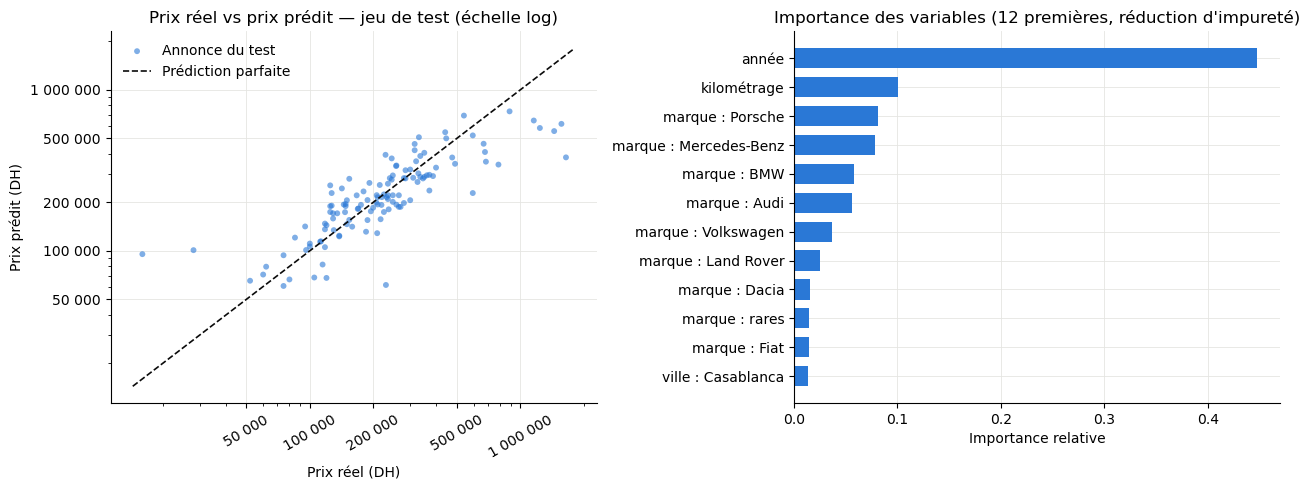

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
ax.scatter(y_test, pred_rf, s=18, color=COULEUR, alpha=0.6, edgecolors="none", label="Annonce du test")
bornes = [min(y_test.min(), pred_rf.min()) * 0.9, max(y_test.max(), pred_rf.max()) * 1.1]
ax.plot(bornes, bornes, color=ENCRE, linewidth=1.2, linestyle="--", label="Prédiction parfaite")
ax.set_xscale("log"); ax.set_yscale("log")
for axe in (ax.xaxis, ax.yaxis):
    axe.set_major_formatter(format_dh); axe.set_minor_formatter(FuncFormatter(lambda x, _: ""))
ax.set_xticks([50000, 100000, 200000, 500000, 1000000]); ax.set_yticks([50000, 100000, 200000, 500000, 1000000])
ax.set_title("Prix réel vs prix prédit — jeu de test (échelle log)")
ax.set_xlabel("Prix réel (DH)"); ax.set_ylabel("Prix prédit (DH)")
ax.tick_params(axis="x", labelrotation=30)
ax.legend(frameon=False)

ax = axes[1]
noms = modele.named_steps["pretraitement"].get_feature_names_out()
importances = pd.Series(modele.named_steps["regresseur"].regressor_.feature_importances_, index=noms)
importances.index = (importances.index.str.replace("annee__annee", "année").str.replace("kilometrage__kilometrage", "kilométrage").str.replace("kilometrage__", "")
                     .str.replace("marque__marque_", "marque : ").str.replace("ville__ville_", "ville : ")
                     .str.replace("missingindicator_kilometrage", "km manquant").str.replace("infrequent_sklearn", "rares"))
top = importances.sort_values().tail(12)
ax.barh(top.index, top.values, color=COULEUR, height=0.7)
ax.set_title("Importance des variables (12 premières, réduction d'impureté)")
ax.set_xlabel("Importance relative")
for a in axes:
    a.grid(color=GRILLE, linewidth=0.6); a.set_axisbelow(True)
    for cote in ("top", "right"):
        a.spines[cote].set_visible(False)
fig.tight_layout()
plt.show()

In [7]:
erreurs = pd.DataFrame({"marque": X_test["marque"], "prix réel": y_test, "prix prédit": pred_rf})
erreurs["erreur absolue"] = (erreurs["prix prédit"] - erreurs["prix réel"]).abs()
print("Les 5 plus grosses erreurs du test :")
print(erreurs.sort_values("erreur absolue", ascending=False).head(5).map(lambda v: fmt(v) if isinstance(v, float) else v).to_string())

Les 5 plus grosses erreurs du test :
            marque  prix réel prix prédit erreur absolue
361     Land Rover  1 650 000     380 782      1 269 218
509           Audi  1 570 000     615 063        954 937
480  Mercedes-Benz  1 450 000     554 682        895 318
234        Porsche  1 240 000     579 791        660 209
374  Mercedes-Benz  1 160 000     645 236        514 764


**Interprétation**

- Le Random Forest **fait nettement mieux que la baseline** sur le même
  jeu de test (n = 124) :
  - MAE de 94 283 DH contre 151 097 DH, soit une réduction de 37,6 % ;
  - RMSE de 202 281 DH contre 289 327 DH ;
  - R² de 0,471 contre −0,081.
  Le critère de succès principal du Step 0 est donc atteint.
- Le R² reste **en dessous de l'objectif indicatif d'environ 0,6**. Le
  modèle explique une partie du prix, mais pas l'essentiel de sa variance.
  L'erreur relative médiane est d'environ 20 %.
- Le RMSE est tiré vers le haut par les **véhicules de luxe très chers**,
  que le modèle sous-estime fortement (Land Rover Defender à 1 650 000 DH
  prédit à environ 380 000 DH, par exemple). Deux causes :
  - ces véhicules sont rares dans le train ;
  - un Random Forest fait la moyenne de ses feuilles, et l'apprentissage
    sur le log du prix tire encore les prédictions vers le centre.
- **Limites** :
  - les 4 variables ignorent le modèle exact (un Range Rover Evoque et un
    Defender partagent la marque Land Rover), la motorisation, l'état, les
    options et la négociation ;
  - le jeu de test est petit (124 annonces), ce qui rend les métriques
    sensibles au découpage ;
  - une marque ou une ville regroupée comme « rare » reçoit une estimation
    moins spécifique.

## 5. Sauvegarde des artefacts

On sauvegarde le **pipeline complet** (imputation, indicateur, encodage,
Random Forest et transformation de la cible) : l'application n'a aucun
prétraitement à refaire. Les métadonnées donnent à l'application les
listes de marques et villes, les plages de saisie et les métriques.

In [8]:
DOSSIER = Path("../artifacts/regression")
DOSSIER.mkdir(parents=True, exist_ok=True)
joblib.dump(modele, DOSSIER / "modele_prix.joblib")

metadata = {
    "variables_entree": VARIABLES,
    "cible": CIBLE,
    "transformation_cible": "log1p / expm1 (TransformedTargetRegressor)",
    "marques": sorted(df["marque"].unique().tolist()),
    "villes": sorted(df["ville"].unique().tolist()),
    "marques_regroupees_rares": marques_rares,
    "villes_regroupees_rares": villes_rares,
    "seuils_regroupement": {"marque": 10, "ville": 15},
    "annee_min": int(df["annee"].min()),
    "annee_max": int(df["annee"].max()),
    "kilometrage_max": 500000,
    "mediane_imputation_kilometrage": float(encodeurs["kilometrage"].statistics_[0]),
    "metriques_test": {nom: {k: float(v) for k, v in ligne.items()} for nom, ligne in resultats.iterrows()},
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "random_state": RANDOM_STATE,
    "version_sklearn": sklearn.__version__,
}
(DOSSIER / "metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
print("Artefacts sauvegardés :")
for f in sorted(DOSSIER.iterdir()):
    print(f"  {f.name} ({f.stat().st_size / 1024:.0f} Ko)")

Artefacts sauvegardés :
  metadata.json (3 Ko)
  modele_prix.joblib (5796 Ko)


In [9]:
# Vérification : rechargement et prédiction
modele_recharge = joblib.load(DOSSIER / "modele_prix.joblib")
assert np.allclose(modele_recharge.predict(X_test), pred_rf), "Le modèle rechargé ne donne pas les mêmes prédictions"
exemples = pd.DataFrame([
    {"annee": 2020, "kilometrage": 90000, "marque": "Dacia", "ville": "Casablanca"},
    {"annee": 2022, "kilometrage": np.nan, "marque": "Mercedes-Benz", "ville": "Rabat"},
    {"annee": 2018, "kilometrage": 120000, "marque": "Marque inconnue", "ville": "Ville inconnue"},
])
exemples["prix prédit (DH)"] = modele_recharge.predict(exemples[VARIABLES]).round(0)
print("Modèle rechargé : prédictions identiques sur le test.")
print("Exemples (km manquant, marque et ville inconnues gérés) :")
exemples

Modèle rechargé : prédictions identiques sur le test.
Exemples (km manquant, marque et ville inconnues gérés) :


,annee,kilometrage,marque,ville,prix prédit (DH)
0,2020,90000.0,Dacia,Casablanca,163192.0
1,2022,NaN,Mercedes-Benz,Rabat,424445.0
2,2018,120000.0,Marque inconnue,Ville inconnue,217953.0
